# k-nearest neighbors, Schritt für Schritt

**Frage des Projekts:** Können wir vorhersagen, welche Teilnehmenden ihren Job wechseln wollen (`job_change`)?

Dieses Notebook wendet kNN auf unsere fertig aufbereiteten Daten an. Es folgt dem Aufbau von Kapitel 3 der Vorlesung und ergänzt die Methodik aus DataCamp, *Supervised Learning with scikit-learn*, Kapitel 1.

| Schritt | Was passiert | Vorlesung |
|---|---|---|
| 1 | Vorhersageaufgabe festlegen | Frame |
| 2 | Daten laden, Features und Ziel trennen, Voraussetzungen prüfen | Frame, Before you use supervised learning |
| 3 | Baseline bestimmen | Class imbalance |
| 4 | Preprocessing bauen (Encoding und Skalierung) | Prepare |
| 5 | kNN von Hand nachrechnen, scikit-learn-Grammatik, Entscheidungsgrenze | k-nearest neighbors, KNN Intuition |
| 6 | Erstes Modell, Trainings-Accuracy und Holdout-Split | Measure, Train/test split |
| 7 | 5-fach Cross-Validation und Wahl des Encodings | Validate |
| 8 | Modellkomplexität: Kurven über k und Entscheidungsgrenzen | Model complexity |
| 9 | Hyperparameter-Tuning und Prüfung der Features | Validate |
| 10 | Schwellenwert aus Kosten wählen | Decide |
| 11 | Einmalige Auswertung auf dem Testset | Evaluate, Decide |
| 12 | Fazit | Wrap-up |

**Die wichtigste Regel:** Alle Entscheidungen (Encoding, k, Schwellenwert) fallen auf den Trainingsdaten. Das Testset wird erst in Schritt 11 und nur einmal benutzt.

## 0. Setup

Alle Bibliotheken an einer Stelle. `RANDOM_STATE` macht die Ergebnisse reproduzierbar. Ohne festen Wert würde jede Ausführung die Daten anders mischen, und die Zahlen im Text würden nicht mehr zu den Ausgaben passen. Blau steht wie in der Vorlesung für "kein Wechsel" beziehungsweise Training, Rot für "Wechsel" beziehungsweise Validierung.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (ConfusionMatrixDisplay, accuracy_score, confusion_matrix,
                             f1_score, precision_score, recall_score,
                             roc_auc_score, roc_curve)
from sklearn.metrics.pairwise import euclidean_distances
from sklearn.model_selection import (GridSearchCV, StratifiedKFold, cross_val_predict,
                                     cross_validate, train_test_split)
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder, OrdinalEncoder, StandardScaler

RANDOM_STATE = 42
BLUE, RED, INK, GRID = "#2878D8", "#B22E2E", "#262B31", "#E6E8EB"

plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": "#9AA0A6", "axes.labelcolor": INK, "xtick.color": "#5F6670",
    "ytick.color": "#5F6670", "axes.grid": True, "grid.color": GRID, "axes.axisbelow": True,
    "lines.linewidth": 2, "legend.frameon": False,
})

## 1. Die Vorhersageaufgabe

**Einordnung (DataCamp, Kapitel 1):** Machine Learning bedeutet, dass ein Computer aus Daten lernt, Entscheidungen zu treffen, ohne dass die Regeln explizit programmiert werden.

| Begriff | Bedeutung | Bei uns |
|---|---|---|
| **Supervised Learning** | Die richtigen Antworten sind in den Trainingsdaten bekannt. Ziel ist die Vorhersage für ungesehene Daten. | Ja: `job_change` ist bekannt |
| Unsupervised Learning | Keine Antworten, das Modell sucht verborgene Muster, zum Beispiel Cluster | Nein |
| **Klassifikation** | Das Ziel besteht aus Kategorien | Ja: Wechsel oder kein Wechsel |
| Regression | Das Ziel ist kontinuierlich | Nein |
| **Feature** | auch: Predictor oder unabhängige Variable | die 10 Spalten in `X` |
| **Target** | auch: Response oder abhängige Variable | `job_change` in `y` |

Die Vorlesung verlangt vier Festlegungen, bevor modelliert wird:

| Frage | Unsere Antwort |
|---|---|
| **Target** | `job_change`: 1 = will wechseln, 0 = will nicht wechseln. Zwei Klassen, also **Klassifikation**. |
| **Unit** | eine teilnehmende Person (eine Zeile) |
| **Moment** | der Zeitpunkt, zu dem das Profil der Person und ihre Trainingsstunden bekannt sind |
| **Decision** | Wen spricht das Recruiting gezielt an? |

**Welche Features sind erlaubt?**

- `student_id` nicht: reine Nummer ohne Bedeutung.
- `city` nicht: 123 Ausprägungen würden den Distanzraum aufblähen, `city_development_index` beschreibt die Stadt bereits.
- `gender` nicht: wurde schon im Imputation-Notebook aus Fairness-Gründen entfernt.
- Alle übrigen Spalten sind zum Vorhersagezeitpunkt bekannt.

## 2. Daten laden, Features und Ziel trennen

Wir laden die beiden Dateien aus `missing_values_imputation.ipynb`. Sie sind bereits vollständig gefüllt und bereits geteilt, **wir splitten also nicht noch einmal**.

**Warum nicht neu splitten?** Die Lücken wurden mit Werten gefüllt, die nur aus dem Trainingsteil gelernt wurden. Ein neuer Split würde Personen vermischen, und das Testset wäre nicht mehr unabhängig.

**Warum Features und Ziel trennen?** Wäre `job_change` in `X`, könnte das Modell die Antwort einfach ablesen. Es muss sie aus den anderen Spalten erschließen, denn bei neuen Personen ist sie unbekannt.

Zwei technische Anpassungen für scikit-learn: `relevant_experience` wird von True/False zu 1/0, und die `category`-Spalten werden zu normalen Textspalten, damit die Encoder sie einheitlich behandeln.

In [2]:
train = pd.read_pickle("customer_train_final_train.pkl")
test = pd.read_pickle("customer_train_final_test.pkl")


def split_features_target(df):
    X = df.drop(columns=["student_id", "city", "job_change"]).copy()
    y = df["job_change"].astype(int)
    X["relevant_experience"] = X["relevant_experience"].astype(int)
    for col in X.select_dtypes("category").columns:
        X[col] = X[col].astype(object)
    return X, y


X_train, y_train = split_features_target(train)
X_test, y_test = split_features_target(test)

print("Training:", X_train.shape, "| Anteil Wechsel:", round(y_train.mean(), 3))
print("Test:    ", X_test.shape, "| Anteil Wechsel:", round(y_test.mean(), 3))
print("Fehlende Werte:", int(X_train.isna().sum().sum() + X_test.isna().sum().sum()))
X_train.head(3)

Training: (15326, 10) | Anteil Wechsel: 0.249
Test:     (3832, 10) | Anteil Wechsel: 0.249
Fehlende Werte: 0


,city_development_index,relevant_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours
17855,0.624023,1,no_enrollment,Graduate,STEM,10,50-99,Pvt Ltd,1,90
17664,0.919922,0,no_enrollment,Primary School,No Major,5,Unknown,Unknown,never,15
13404,0.895996,1,no_enrollment,Graduate,STEM,12,1000-4999,NGO,>4,36


**Ergebnis:** 15.326 Personen zum Trainieren und 3.832 zum Testen, jeweils mit 10 Features. In beiden Teilen wollen 24,9 % wechseln, die Verteilung ist also gleich. Es fehlen keine Werte mehr.

### Voraussetzungen für Supervised Learning

DataCamp nennt vier Bedingungen, bevor ein Modell trainiert werden darf:

| Voraussetzung | Status |
|---|---|
| Keine fehlenden Werte | erfüllt durch `missing_values_imputation.ipynb`, wird unten geprüft |
| Daten im numerischen Format | noch nicht: 7 Spalten sind Text. Das löst das Preprocessing in Schritt 4 |
| Daten als DataFrame oder NumPy-Array | erfüllt, wird unten geprüft |
| Explorative Datenanalyse zuerst | erfüllt: Woche 2 (`aq_analysis.ipynb`, `key_findings.md`) und `missing_values_overview.ipynb` |

In [3]:
print("Fehlende Werte:", int(X_train.isna().sum().sum()))
print("Datentyp von X_train:", type(X_train).__name__)
print("Spalten, die noch keine Zahlen sind:", list(X_train.select_dtypes(exclude="number").columns))

Fehlende Werte: 0
Datentyp von X_train: DataFrame
Spalten, die noch keine Zahlen sind: ['enrolled_university', 'education_level', 'major_discipline', 'experience', 'company_size', 'company_type', 'last_new_job']


## 3. Baseline: Was erreicht ein Modell ohne Wissen?

Ein Modell ist nur dann nützlich, wenn es eine triviale Regel schlägt. Die trivialste Regel hier: **Sage immer "kein Wechsel" voraus.** Das entspricht dem Beispiel "approve everyone" aus der Vorlesung.

In [4]:
baseline = DummyClassifier(strategy="most_frequent")
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

scores = cross_validate(baseline, X_train, y_train, cv=cv,
                        scoring=["accuracy", "recall", "roc_auc"])
print(f"Baseline Accuracy: {scores['test_accuracy'].mean():.3f}")
print(f"Baseline Recall:   {scores['test_recall'].mean():.3f}")
print(f"Baseline ROC AUC:  {scores['test_roc_auc'].mean():.3f}")

Baseline Accuracy: 0.751
Baseline Recall:   0.000
Baseline ROC AUC:  0.500


**Was das bedeutet:** Die Regel erreicht rund 75 % Accuracy und findet trotzdem keine einzige wechselwillige Person (Recall 0). Accuracy allein ist hier also eine schwache Kennzahl. Darum wählen wir die Modelle über **ROC AUC** aus, und 0,5 ist dabei die Marke für "kein Wissen".

**Warum gerade AUC?** Die Accuracy zählt nur richtige Antworten bei einer festen Schwelle. Weil 75 % der Personen nicht wechseln, kann man sie schon durch Raten der großen Klasse hoch halten. Der AUC prüft stattdessen die **Reihenfolge**: Bekommt eine wechselwillige Person ein höheres Risiko als eine andere, die nicht wechselt? Die Baseline gibt allen denselben Wert, kann also nicht sortieren und landet genau bei 0,5.

## 4. Preprocessing: Daten für Distanzen vorbereiten

kNN vergleicht Personen über **Distanzen**. Daraus folgen zwei Anforderungen:

1. **Alles muss eine Zahl sein.** Kategorien müssen also encodiert werden.
2. **Alles muss auf einer vergleichbaren Skala liegen.** `training_hours` reicht bis 336, `city_development_index` nur bis 0,95. Ohne Skalierung entscheidet praktisch nur `training_hours` über die Distanz.

**Das Problem an einem Beispiel:** Zwei Personen unterscheiden sich beim Index um 0,3 (ein großer Unterschied) und bei den Trainingsstunden um 10 (ein kleiner Unterschied). Die euklidische Distanz ist dann √(0,3² + 10²) ≈ 10,004, der Index spielt also fast keine Rolle. Der `StandardScaler` rechnet deshalb jede Zahl um in (Wert − Mittelwert) / Standardabweichung. Danach bedeutet "1" in jeder Spalte: eine typische Streuung entfernt.

**Warum nicht einfach Nummern für Kategorien?** Würde man `company_type` als Startup = 0, NGO = 2 und Pvt Ltd = 5 codieren, läge Pvt Ltd für kNN weiter von Startup entfernt als NGO. Diese Abstände wären erfunden. Beim One-hot-Encoding bekommt jede Kategorie eine eigene 0/1-Spalte, und zwei verschiedene Kategorien sind immer gleich weit voneinander entfernt.

Für das Encoding gibt es bei uns zwei sinnvolle Varianten:

| Variante | Idee | Herkunft |
|---|---|---|
| **A: one-hot** | alle Kategorien als 0/1-Spalten, Zahlen mit `StandardScaler` | Plan aus dem Imputation-Notebook |
| **B: ordinal** | Spalten mit natürlicher Reihenfolge als Rangzahl, Rest one-hot, alles mit `MinMaxScaler` auf 0 bis 1 | `knn_methode.ipynb` |

Variante B behält die Reihenfolge: 10 Jahre Erfahrung liegen dann nah an 11 Jahren. In Variante A sind 10 und 22 Jahre genauso "verschieden" wie 10 und 11. Wir entscheiden in Schritt 7 per Cross-Validation.

`company_size` ist in beiden Varianten nominal, weil die Kategorie "Unknown" keinen Platz in der Größenreihenfolge hat.

**Warum eine Pipeline?** Encoder und Scaler lernen aus den Daten (zum Beispiel Mittelwert und Streuung). In einer `Pipeline` passiert das in jedem CV-Durchlauf nur auf dem jeweiligen Trainingsteil. So fließt keine Information aus den Validierungsdaten ein (Data Leakage).

In [5]:
numeric_cols = ["city_development_index", "training_hours"]
binary_cols = ["relevant_experience"]
ordinal_order = {
    "education_level": ["Primary School", "High School", "Graduate", "Masters", "Phd"],
    "experience": ["<1"] + [str(i) for i in range(1, 21)] + [">20"],
    "last_new_job": ["never", "1", "2", "3", "4", ">4"],
}
ordinal_cols = list(ordinal_order)
nominal_cols = ["enrolled_university", "major_discipline", "company_size", "company_type"]


def make_preprocessor(variant="ordinal", scale=True, exclude=()):
    '''Variante "onehot" (A) oder "ordinal" (B). scale=False dient nur dem Vergleich unten,
    exclude dient der Feature-Prüfung in Schritt 9b.'''
    keep = lambda cols: [c for c in cols if c not in exclude]
    num, binary, ord_cols, nom = keep(numeric_cols), keep(binary_cols), keep(ordinal_cols), keep(nominal_cols)
    onehot = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
    if variant == "onehot":
        scaler = StandardScaler() if scale else "passthrough"
        return ColumnTransformer([
            ("num", scaler, num),
            ("bin", "passthrough", binary),
            ("cat", onehot, ord_cols + nom),
        ])
    scaler = MinMaxScaler() if scale else "passthrough"
    ordinal = Pipeline([
        ("enc", OrdinalEncoder(categories=[ordinal_order[c] for c in ord_cols])),
        ("scale", MinMaxScaler()),
    ])
    return ColumnTransformer([
        ("num", scaler, num),
        ("bin", "passthrough", binary),
        ("ord", ordinal, ord_cols),
        ("nom", onehot, nom),
    ])


def make_knn(variant="ordinal", scale=True, k=15, exclude=()):
    return Pipeline([
        ("pre", make_preprocessor(variant, scale, exclude)),
        ("knn", KNeighborsClassifier(n_neighbors=k)),
    ])


for variant in ["onehot", "ordinal"]:
    n = make_preprocessor(variant).fit_transform(X_train).shape[1]
    print(f"Variante {variant}: {n} Spalten nach dem Encoding")

# Voraussetzung aus Schritt 2: Nach dem Preprocessing ist alles numerisch und vollständig
encoded = make_preprocessor("onehot").fit_transform(X_train)
print("Alles numerisch:", np.issubdtype(encoded.dtype, np.number), "| Fehlende Werte:", int(np.isnan(encoded).sum()))

Variante onehot: 62 Spalten nach dem Encoding
Variante ordinal: 32 Spalten nach dem Encoding
Alles numerisch: True | Fehlende Werte: 0


**Lohnt sich die Skalierung wirklich?** Wir vergleichen dasselbe Modell (k = 15) mit und ohne Skalierung. Gemessen wird mit 5-facher Cross-Validation, die Schritt 7 genauer erklärt.

In [6]:
for scale in [False, True]:
    auc = cross_validate(make_knn("ordinal", scale=scale, k=15), X_train, y_train,
                         cv=cv, scoring="roc_auc", n_jobs=-1)["test_score"]
    label = "mit Skalierung " if scale else "ohne Skalierung"
    print(f"{label}: ROC AUC = {auc.mean():.3f} ± {auc.std():.3f}")

ohne Skalierung: ROC AUC = 0.657 ± 0.005


mit Skalierung : ROC AUC = 0.755 ± 0.005


**Ergebnis:** Ohne Skalierung liegt der AUC bei 0,657, mit Skalierung bei 0,755. Bei kNN ist Skalierung also kein Detail, sondern Voraussetzung.

Bis zur Entscheidung in Schritt 7 arbeiten wir mit Variante B, weil sich damit die Nachbarn im nächsten Schritt leichter lesen lassen.

## 5. kNN einmal von Hand

Bevor scikit-learn die Arbeit übernimmt, rechnen wir die Methode für eine einzelne Person nach:

1. Eine Person aus den Trainingsdaten herausnehmen und so tun, als wäre sie neu.
2. Ihre Distanz zu allen anderen Personen berechnen.
3. Die k kleinsten Distanzen suchen.
4. Die k Nachbarn abstimmen lassen.

**Warum nehmen wir die Person heraus?** Sonst wäre sie mit Distanz 0 ihr eigener nächster Nachbar und würde ihre eigene Antwort abschreiben.

**Wie wird die Distanz berechnet?** Die Differenzen aller Spalten werden quadriert, addiert, und daraus wird die Wurzel gezogen: d = √((a₁ − b₁)² + (a₂ − b₂)² + …). Je kleiner d, desto ähnlicher sind sich zwei Personen. Dahinter steht die Grundannahme von kNN: **Ähnliche Personen verhalten sich ähnlich.**

In [7]:
probe, rest = X_train.iloc[[0]], X_train.iloc[1:]
y_rest = y_train.iloc[1:].to_numpy()

# Der Preprocessor lernt nur von den anderen Personen, die "neue" Person bleibt außen vor
pre = make_preprocessor("ordinal").fit(rest)
distances = euclidean_distances(pre.transform(probe), pre.transform(rest)).ravel()
nearest = np.argsort(distances, kind="stable")   # Positionen, sortiert von nah nach fern

print("Neue Person:")
display(probe.assign(job_change_wahr=y_train.iloc[0]))

print("Ihre fünf nächsten Nachbarn:")
display(rest.iloc[nearest[:5]].assign(distanz=distances[nearest[:5]].round(3),
                                      job_change=y_rest[nearest[:5]]))

print("Abstimmung bei verschiedenen k:")
for k in [1, 3, 5, 15, 75]:
    share = y_rest[nearest[:k]].mean()
    print(f"k = {k:>2}: {share:6.1%} der Nachbarn wechseln -> Vorhersage: "
          f"{'Wechsel' if share >= 0.5 else 'kein Wechsel'}")

Neue Person:


,city_development_index,relevant_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,job_change_wahr
17855,0.624023,1,no_enrollment,Graduate,STEM,10,50-99,Pvt Ltd,1,90,0


Ihre fünf nächsten Nachbarn:


,city_development_index,relevant_experience,enrolled_university,education_level,major_discipline,experience,company_size,company_type,last_new_job,training_hours,distanz,job_change
9341,0.624023,1,no_enrollment,Graduate,STEM,11,50-99,Pvt Ltd,1,67,0.084,1
13420,0.579102,1,no_enrollment,Graduate,STEM,10,50-99,Pvt Ltd,1,78,0.097,1
8249,0.624023,1,no_enrollment,Graduate,STEM,12,50-99,Pvt Ltd,1,77,0.103,1
5090,0.624023,1,no_enrollment,Graduate,STEM,10,50-99,Pvt Ltd,1,46,0.131,1
8955,0.624023,1,no_enrollment,Graduate,STEM,7,50-99,Pvt Ltd,1,109,0.154,0


Abstimmung bei verschiedenen k:
k =  1: 100.0% der Nachbarn wechseln -> Vorhersage: Wechsel
k =  3: 100.0% der Nachbarn wechseln -> Vorhersage: Wechsel
k =  5:  80.0% der Nachbarn wechseln -> Vorhersage: Wechsel
k = 15:  46.7% der Nachbarn wechseln -> Vorhersage: kein Wechsel
k = 75:  44.0% der Nachbarn wechseln -> Vorhersage: kein Wechsel


**Was wir sehen:**

- Die Nachbarn sehen der Person tatsächlich sehr ähnlich: gleiche Ausbildung, gleiches Fach, gleiche Firmengröße und -art, fast derselbe `city_development_index`. Die Distanz bildet Ähnlichkeit also sinnvoll ab.
- **Dieselbe Person bekommt je nach k eine andere Antwort.** Bei k = 1, 3 und 5 lautet die Vorhersage "Wechsel", bei k = 15 und 75 "kein Wechsel". Die Person will in Wirklichkeit nicht wechseln.
- Das ist genau der Effekt aus der Vorlesung: Die Wahl von k ist entscheidend und muss sauber begründet werden.

### 5b. Die scikit-learn-Grammatik: erstellen, `fit`, `predict`

Jetzt dasselbe mit scikit-learn, bewusst klein mit nur zwei Features und k = 15, wie im DataCamp-Beispiel:

- `X` ist ein NumPy-Array mit einer Zeile pro Person und einer Spalte pro Feature.
- `y` enthält die bekannten Antworten.
- `X_new` sind **neue Personen ohne Antwort**, wieder mit einer Zeile pro Person.

Eine Abweichung vom DataCamp-Beispiel: Unsere zwei Features haben sehr unterschiedliche Skalen, deshalb steht ein `StandardScaler` vor dem Modell.

> **Wichtig: Das ist nur ein Anschauungsbeispiel.** Das Mini-Modell `knn_two` fließt nicht in das Ergebnis ein. Das endgültige Modell ab Schritt 6 nutzt alle 10 Features.
>
> **Warum diese zwei Spalten?** `city_development_index` und `training_hours` sind die einzigen echten Zahlenspalten. Sie brauchen kein Encoding und lassen sich in 5c als Achsen zeichnen. Nach Vorhersagekraft sind sie nicht ausgewählt.

In [8]:
two_features = ["city_development_index", "training_hours"]
X_two = X_train[two_features].values
y_two = y_train.values
print("X:", X_two.shape, "| y:", y_two.shape)

knn_two = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=15))   # 1. erstellen
knn_two.fit(X_two, y_two)                                                         # 2. lernen

X_new = np.array([[0.55, 40],     # Stadt mit niedrigem Entwicklungsindex
                  [0.92, 40],     # Stadt mit hohem Entwicklungsindex
                  [0.92, 200]])   # hoher Index, viele Trainingsstunden
print("X_new:", X_new.shape)

print("Vorhersagen:", knn_two.predict(X_new))                                     # 3. vorhersagen
print("Anteil wechselnder Nachbarn:", knn_two.predict_proba(X_new)[:, 1].round(2))

X: (15326, 2) | y: (15326,)
X_new: (3, 2)
Vorhersagen: [1 0 0]
Anteil wechselnder Nachbarn: [0.6  0.2  0.47]


**Ergebnis:** `[1 0 0]`. Nur die erste Person aus einer Stadt mit niedrigem Entwicklungsindex wird als wechselwillig eingestuft (60 % der Nachbarn wechseln). Die dritte Person liegt mit 47 % knapp unter der Mehrheit. Solche Fälle zeigen, warum der Schwellenwert in Schritt 10 eine eigene Entscheidung ist.

### 5c. Entscheidungsgrenze

Mit zwei Features lässt sich kNN zeichnen. Jeder Punkt der Fläche wird eingefärbt, je nachdem, wie seine 15 nächsten Nachbarn abstimmen. Die Grenze zwischen den Farben heißt **Entscheidungsgrenze**. Jede neue Person landet in einem der Bereiche und bekommt dessen Vorhersage.

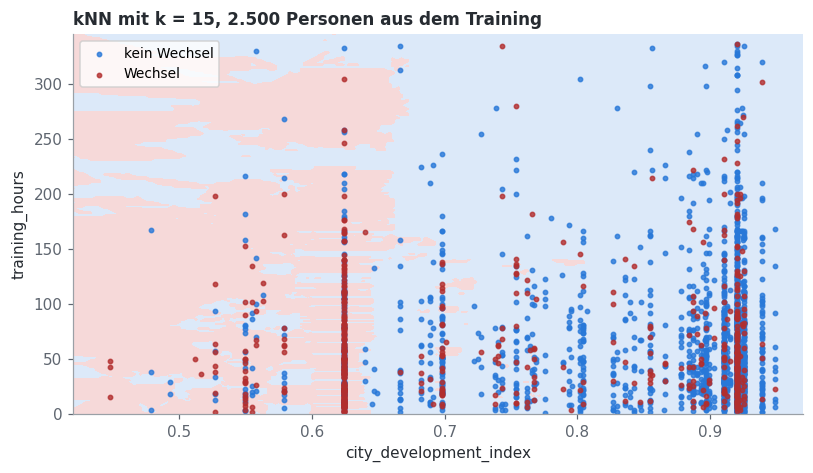

In [9]:
def plot_boundary(ax, model, X, y, point_size=8):
    '''Färbt die Fläche nach der Vorhersage von model ein und zeichnet die Personen darüber.'''
    xx, yy = np.meshgrid(np.linspace(0.42, 0.97, 250), np.linspace(0, 345, 250))
    Z = model.predict(np.c_[xx.ravel(), yy.ravel()]).reshape(xx.shape)
    ax.contourf(xx, yy, Z, levels=[-0.5, 0.5, 1.5], colors=["#DCE9F9", "#F6D9D9"])
    ax.scatter(X[y == 0, 0], X[y == 0, 1], s=point_size, color=BLUE, alpha=0.8, label="kein Wechsel")
    ax.scatter(X[y == 1, 0], X[y == 1, 1], s=point_size, color=RED, alpha=0.8, label="Wechsel")
    ax.grid(False)
    ax.set_xlabel("city_development_index")


rng = np.random.default_rng(RANDOM_STATE)
sample = rng.choice(len(X_two), size=2500, replace=False)

fig, ax = plt.subplots(figsize=(7.5, 4.4))
plot_boundary(ax, knn_two, X_two[sample], y_two[sample])
ax.set_ylabel("training_hours")
ax.set_title("kNN mit k = 15, 2.500 Personen aus dem Training", loc="left", color=INK, fontsize=11, fontweight="bold")
ax.legend(loc="upper left", fontsize=9, frameon=True)
plt.tight_layout()
plt.show()

**So liest du die Grafik**

- **Achsen:** Nach rechts steigt der `city_development_index`, nach oben die Trainingsstunden. Jeder Punkt ist eine Person.
- **Hintergrund = Vorhersage:** Auf rosa Fläche sagt das Modell "Wechsel" voraus, auf blauer "kein Wechsel".
- **Punktfarbe = Wahrheit:** Rot will wirklich wechseln, Blau nicht. Ein roter Punkt auf blauer Fläche ist also eine übersehene Person, ein blauer Punkt auf rosa Fläche ein Fehlalarm.

**Beispiel:** Eine neue Person mit Index 0,62 und 50 Trainingsstunden landet auf der rosa Fläche, die Vorhersage lautet also "Wechsel". Bei Index 0,92 und ebenfalls 50 Stunden liegt sie auf der blauen Fläche und bekommt "kein Wechsel".

**Was wir sehen:** Links, bei einem niedrigen `city_development_index`, überwiegt die Vorhersage "Wechsel", rechts "kein Wechsel". Die Trainingsstunden spielen sichtbar eine kleinere Rolle. Die vielen senkrechten Punktreihen entstehen, weil der Index nur wenige verschiedene Werte annimmt.

Gelernt hat das Modell auf allen 15.326 Trainingspersonen, gezeichnet sind zur Übersicht nur 2.500. Das Bild zeigt außerdem nur zwei Features, unser endgültiges Modell nutzt alle zehn.

## 6. Erstes Modell: Warum Trainings-Accuracy nichts aussagt

Die Grammatik ist bei jedem scikit-learn-Modell gleich: **erstellen, `fit`, `predict`**. Bei kNN ist `fit` fast leer, das Modell speichert nur die Trainingsdaten. Gerechnet wird erst bei der Vorhersage. Deshalb gibt es keine Gewichte oder Formel, die kNN "gelernt" hätte: Die Trainingsdaten selbst sind das Modell.

Mit k = 1 messen wir nun die Accuracy auf den eigenen Trainingsdaten und auf Daten, die das Modell nicht kennt.

In [10]:
result = cross_validate(make_knn("ordinal", k=1), X_train, y_train, cv=cv,
                        scoring="accuracy", return_train_score=True, n_jobs=-1)
print(f"k = 1, Accuracy auf den eigenen Trainingsdaten: {result['train_score'].mean():.3f}")
print(f"k = 1, Accuracy auf ungesehenen Daten:          {result['test_score'].mean():.3f}")

k = 1, Accuracy auf den eigenen Trainingsdaten: 0.998
k = 1, Accuracy auf ungesehenen Daten:          0.712


**Ergebnis:** Auf den eigenen Trainingsdaten erreicht das Modell 99,8 %, auf ungesehenen Daten nur 71,2 %. Das liegt sogar **unter der Baseline** von 75,1 %.

Bei k = 1 findet jede Person sich selbst als nächsten Nachbarn, das Modell lernt die Daten also auswendig. Dass es nicht exakt 100 % sind, liegt vermutlich an Personen mit identischem Profil, aber unterschiedlichem Ergebnis.

**Konsequenz:** Ab jetzt zählt nur noch die Leistung auf Daten, die das Modell beim Lernen nicht gesehen hat.

### 6b. Holdout-Split: Accuracy auf ungesehenen Daten

Der Ablauf aus dem DataCamp-Kurs: **Daten teilen → auf dem Trainingsteil fitten → auf dem zurückgehaltenen Teil die Accuracy berechnen.**

- `test_size=0.3`: 30 % werden zurückgehalten.
- `random_state=21`: Die Aufteilung ist reproduzierbar.
- `stratify=y`: Der Anteil der Wechsler bleibt in beiden Teilen gleich.
- `.score()` berechnet bei einem Klassifikator die Accuracy, also richtige Vorhersagen geteilt durch alle Beobachtungen.

**Wichtig:** Unser echtes Testset bleibt weiter verschlossen. Wir teilen hier nur die Trainingsdaten noch einmal in einen Fit-Teil und einen Validierungsteil (`X_fit`, `X_val`).

**Warum überhaupt zurückhalten?** Wir wollen wissen, wie gut das Modell bei Personen ist, die es noch nie gesehen hat. Das lässt sich nur mit Daten messen, deren Antwort wir kennen, die das Modell beim Lernen aber nicht benutzen durfte.

**Warum `stratify`?** Nur 25 % wollen wechseln. Bei rein zufälligem Teilen könnte dieser Anteil in den Teilen schwanken, und die Teile wären nicht mehr vergleichbar.

Das hier verwendete k = 6 ist nur der Beispielwert aus dem Kurs. Gewählt wird k erst später.

In [11]:
X_fit, X_val, y_fit, y_val = train_test_split(
    X_train, y_train, test_size=0.3, random_state=21, stratify=y_train)
print("Fit-Teil:", X_fit.shape, "| Validierungsteil:", X_val.shape)
print("Anteil Wechsel:", round(y_fit.mean(), 3), "/", round(y_val.mean(), 3))

knn = make_knn("ordinal", k=6)
knn.fit(X_fit, y_fit)
print(f"Accuracy auf dem Validierungsteil (k = 6): {knn.score(X_val, y_val):.3f}")

Fit-Teil: (10728, 10) | Validierungsteil: (4598, 10)
Anteil Wechsel: 0.249 / 0.249
Accuracy auf dem Validierungsteil (k = 6): 0.766


**Ergebnis:** 76,6 % Accuracy bei k = 6, also etwas über der Baseline von 75,1 %. Das ist aber nur eine einzige Aufteilung. Deshalb folgt in Schritt 7 die Cross-Validation.

## 7. Cross-Validation und Wahl des Encodings

Ein einzelner Split ist nur eine Ziehung. Bei der **5-fachen Cross-Validation** werden die Trainingsdaten in fünf Teile geschnitten. Jeder Teil dient genau einmal zur Validierung, während das Modell auf den anderen vier neu lernt. Wir berichten **Mittelwert und Streuung**. `StratifiedKFold` hält den Anteil der Wechsler in jedem Teil gleich.

**Warum ist das besser als ein einzelner Split?** Beim Holdout hängt das Ergebnis davon ab, welche Personen zufällig im Validierungsteil gelandet sind. In der Cross-Validation wird jede Person genau einmal zur Prüfung benutzt. Der Mittelwert ist dadurch stabiler, und die Streuung zeigt, wie stark das Ergebnis schwankt. Unterschiede, die kleiner als diese Streuung sind, sollte man nicht überbewerten.

**Warum wird neu gelernt?** In jedem Durchlauf lernen auch Encoder und Scaler nur aus den vier Trainingsteilen. So bleibt der fünfte Teil wirklich ungesehen.

Damit vergleichen wir die beiden Encoding-Varianten aus Schritt 4 auf denselben fünf Teilen. Weil das beste k noch nicht feststeht, prüfen wir drei Werte. Der Vergleich bei nur einem k könnte zufällig eine Variante bevorzugen.

In [12]:
rows = []
for variant in ["onehot", "ordinal"]:
    for k in [15, 75, 151]:
        auc = cross_validate(make_knn(variant, k=k), X_train, y_train, cv=cv,
                             scoring="roc_auc", n_jobs=-1)["test_score"]
        rows.append({"Variante": variant, "k": k, "AUC Mittelwert": auc.mean(), "AUC Streuung": auc.std()})

encoding_results = pd.DataFrame(rows)
display(encoding_results.pivot(index="k", columns="Variante", values="AUC Mittelwert").round(3))
display(encoding_results.pivot(index="k", columns="Variante", values="AUC Streuung").round(3))

BEST_ENCODING = encoding_results.loc[encoding_results["AUC Mittelwert"].idxmax(), "Variante"]
print("Gewählte Variante:", BEST_ENCODING)

Variante,onehot,ordinal
k,,
15,0.770,0.755
75,0.783,0.769
151,0.785,0.766


Variante,onehot,ordinal
k,,
15,0.008,0.005
75,0.011,0.008
151,0.010,0.009


Gewählte Variante: onehot


**Ergebnis:** One-hot (Variante A) ist bei allen drei k besser. Der Vorsprung von 0,014 bis 0,019 AUC ist größer als die Streuung zwischen den Folds (etwa 0,01), ein reiner Zufall ist er also wohl nicht.

Das hatten wir so nicht erwartet, denn ordinal klang nach der besseren Idee. Eine mögliche Erklärung: Rangzahlen unterstellen gleich große Abstände zwischen den Stufen. One-hot macht diese Annahme nicht.

**Entscheidung:** Wir verwenden ab hier one-hot. Das weicht von `knn_methode.ipynb` ab und entspricht dem Plan aus dem Imputation-Notebook.

## 8. Modellkomplexität: Wie hängt die Güte von k ab?

`k` steuert die Komplexität des Modells:

- **Kleines k:** Das Modell folgt jedem einzelnen Punkt und damit auch dem Rauschen. Gefahr: **Overfitting**.
- **Großes k:** Das Modell mittelt über sehr viele Personen. Gefahr: **Underfitting**.

**Warum ist das so?** kNN schätzt mit seinen Nachbarn im Grunde einen Anteil: "Wie viele Personen wie diese wechseln?" Bei einem wahren Anteil von 25 % schwankt diese Schätzung mit k = 5 um etwa ±19 Prozentpunkte und mit k = 151 nur um etwa ±3,5, denn der Standardfehler ist √(0,25 · 0,75 / k). Wenige Nachbarn liefern also eine verrauschte Antwort. Sehr viele Nachbarn sind aber irgendwann der Person nicht mehr ähnlich, und die Schätzung nähert sich dem Durchschnitt aller Personen.

Die x-Achse ist logarithmisch, weil sich zwischen k = 1 und k = 10 viel mehr ändert als zwischen 100 und 110.

Anders als in der Folie und im DataCamp-Kurs verwenden wir für die Kurve nicht das Testset, sondern die Cross-Validation. Sonst hätten wir k schon am Testset ausgesucht, und das Testset wäre nicht mehr unabhängig.

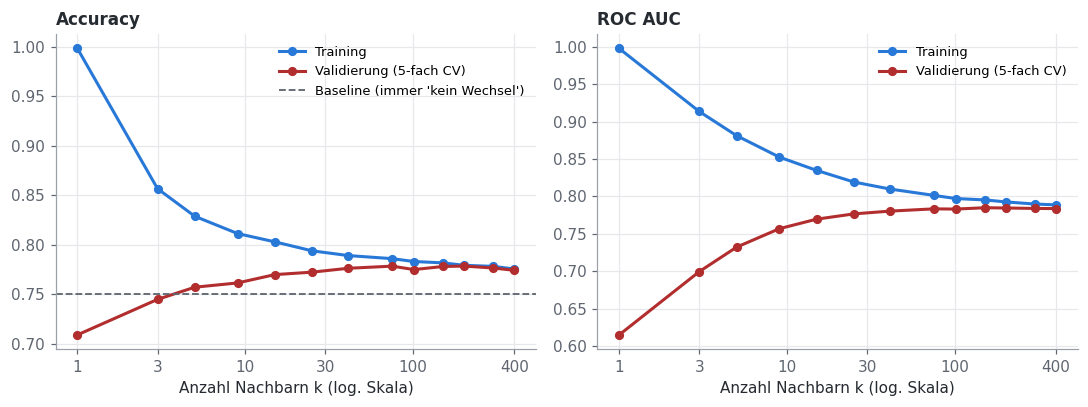

,k,Accuracy Validierung,AUC Training,AUC Validierung,AUC Streuung
0,1,0.709,0.998,0.615,0.004
1,3,0.745,0.914,0.699,0.008
2,5,0.757,0.881,0.732,0.008
3,9,0.762,0.853,0.757,0.007
4,15,0.770,0.835,0.770,0.008
5,25,0.772,0.819,0.777,0.007
6,41,0.776,0.810,0.780,0.008
7,75,0.779,0.801,0.783,0.011
8,101,0.775,0.797,0.783,0.010
9,151,0.778,0.795,0.785,0.010


In [13]:
k_values = [1, 3, 5, 9, 15, 25, 41, 75, 101, 151, 201, 301, 401]

curve = GridSearchCV(make_knn(BEST_ENCODING), {"knn__n_neighbors": k_values},
                     cv=cv, scoring=["accuracy", "roc_auc"], refit=False,
                     return_train_score=True, n_jobs=-1).fit(X_train, y_train)
res = curve.cv_results_

fig, axes = plt.subplots(1, 2, figsize=(10, 3.8), sharex=True)
for ax, metric, title in zip(axes, ["accuracy", "roc_auc"], ["Accuracy", "ROC AUC"]):
    ax.plot(k_values, res[f"mean_train_{metric}"], "-o", ms=5, color=BLUE, label="Training")
    ax.plot(k_values, res[f"mean_test_{metric}"], "-o", ms=5, color=RED, label="Validierung (5-fach CV)")
    ax.set_xscale("log")
    ax.set_xticks([1, 3, 10, 30, 100, 400], labels=["1", "3", "10", "30", "100", "400"])
    ax.minorticks_off()
    ax.set_xlabel("Anzahl Nachbarn k (log. Skala)")
    ax.set_title(title, loc="left", color=INK, fontsize=11, fontweight="bold")
axes[0].axhline(y_train.value_counts(normalize=True).max(), color="#5F6670", ls="--", lw=1.2,
                label="Baseline (immer 'kein Wechsel')")
axes[0].legend(loc="upper right", fontsize=8.5)
axes[1].legend(loc="upper right", fontsize=8.5)
plt.tight_layout()
plt.show()

display(pd.DataFrame({
    "k": k_values,
    "Accuracy Validierung": res["mean_test_accuracy"],
    "AUC Training": res["mean_train_roc_auc"],
    "AUC Validierung": res["mean_test_roc_auc"],
    "AUC Streuung": res["std_test_roc_auc"],
}).round(3))

**So liest du die Grafik**

- **x-Achse:** die Anzahl der Nachbarn k. Die Abstände sind logarithmisch, der Weg von 100 bis 400 ist also genauso lang wie der von 1 bis 4.
- **Blaue Linie:** die Güte auf den Daten, die das Modell schon kennt.
- **Rote Linie:** die Güte auf ungesehenen Daten. Nur sie zählt für die Auswahl.
- **Abstand zwischen den Linien:** Je größer er ist, desto stärker lernt das Modell auswendig.
- **Gestrichelte Linie (links):** die Accuracy der Baseline. Darunter ist das Modell schlechter als immer "kein Wechsel" zu sagen.

**Beispiel (rechtes Bild):** Bei k = 1 liegt der AUC im Training bei 0,998 und in der Validierung bei 0,615. Der Abstand von 0,38 zeigt starkes Overfitting. Bei k = 151 sind es 0,795 und 0,785, der Abstand beträgt nur noch 0,01.

**So lesen wir die Kurven:**

- **Links (k = 1 bis etwa 10): Overfitting.** Bei k = 1 steht der AUC im Training bei 0,998, in der Validierung nur bei 0,615. Die große Lücke zeigt, dass das Modell auswendig lernt.
- **Mitte (ab etwa k = 75): stabil.** Der Validierungs-AUC bleibt zwischen 0,783 und 0,785, und die Kurven nähern sich an. Unterschiede in diesem Bereich sind kleiner als die Streuung (etwa 0,01).
- **Rechts:** Bis k = 401 sehen wir beim AUC noch keinen deutlichen Einbruch durch Underfitting. Die Accuracy geht nur leicht zurück.
- **Baseline:** Die Accuracy liegt erst ab k = 5 über den 75,1 % der Baseline, bei k = 75 erreicht sie 77,9 %.

**Warum steigt der AUC mit k deutlicher als die Accuracy?** Die Accuracy fragt nur, ob die Mehrheit über 50 % liegt. Der AUC nutzt die ganze Rangfolge. Bei k = 1 gibt es nur die Werte 0 und 1, bei k = 151 aber 152 mögliche Anteile. Das Modell kann Personen also viel feiner sortieren.

### 8b. Die DataCamp-Schleife: k = 1 bis 25

Die Kurve von oben noch einmal so, wie sie im Kurs entsteht: eine Schleife über k, die Ergebnisse in zwei Dictionaries, gemessen auf dem Holdout-Split aus Schritt 6b. Damit lässt sich der Bereich der kleinen k in Einerschritten ansehen.

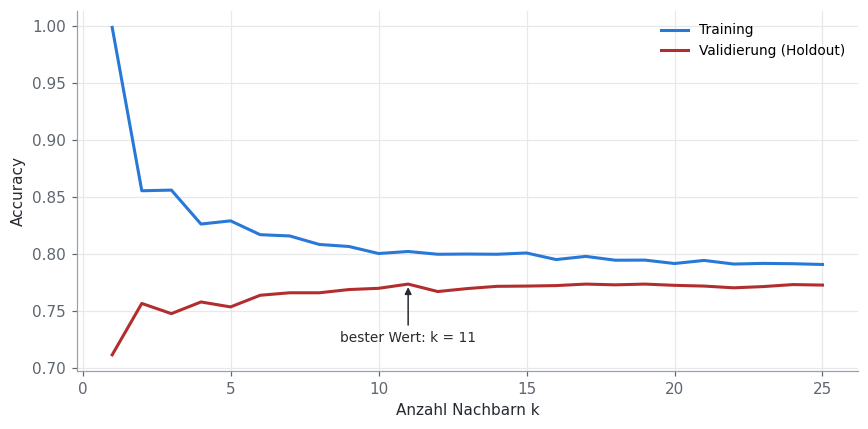

Beste Holdout-Accuracy: 0.774 bei k = 11
Accuracy bei k = 13 bis 25: {13: 0.77, 14: 0.772, 15: 0.772, 16: 0.773, 17: 0.774, 18: 0.773, 19: 0.774, 20: 0.773, 21: 0.772, 22: 0.771, 23: 0.772, 24: 0.773, 25: 0.773}


In [14]:
train_accuracies = {}
val_accuracies = {}
neighbors = np.arange(1, 26)

for neighbor in neighbors:
    knn = make_knn(BEST_ENCODING, k=int(neighbor))
    knn.fit(X_fit, y_fit)
    train_accuracies[neighbor] = knn.score(X_fit, y_fit)
    val_accuracies[neighbor] = knn.score(X_val, y_val)

best_k_holdout = max(val_accuracies, key=val_accuracies.get)

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(neighbors, list(train_accuracies.values()), color=BLUE, label="Training")
ax.plot(neighbors, list(val_accuracies.values()), color=RED, label="Validierung (Holdout)")
ax.annotate(f"bester Wert: k = {best_k_holdout}", xy=(best_k_holdout, val_accuracies[best_k_holdout]),
            xytext=(0, -38), textcoords="offset points", ha="center", color=INK, fontsize=9,
            arrowprops=dict(arrowstyle="-|>", color=INK))
ax.set_xlabel("Anzahl Nachbarn k")
ax.set_ylabel("Accuracy")
ax.legend(loc="upper right", fontsize=9)
plt.tight_layout()
plt.show()

print(f"Beste Holdout-Accuracy: {val_accuracies[best_k_holdout]:.3f} bei k = {best_k_holdout}")
print("Accuracy bei k = 13 bis 25:", {int(k): round(v, 3) for k, v in val_accuracies.items() if k >= 13})

**So liest du die Grafik**

- **x-Achse:** k von 1 bis 25, diesmal in gleichmäßigen Einerschritten.
- **Blau:** Accuracy auf dem Fit-Teil, also den bekannten Daten. **Rot:** Accuracy auf dem zurückgehaltenen Validierungsteil.
- **Pfeil:** das k mit der höchsten roten Linie.

**Beispiel:** Bei k = 1 steht Blau fast bei 1,00 und Rot bei etwa 0,71. Das Modell kennt seine Trainingsdaten perfekt und ist bei neuen Personen schwach. Bei k = 11 liegt Rot bei 0,774 und Blau bei etwa 0,80, die Lücke ist also viel kleiner. Wenn die rote Linie wie hier ab etwa k = 10 nur noch leicht zittert, sind die kleinen Spitzen eher Zufall.

**So lesen wir die Kurve:** Die Trainings-Accuracy fällt von fast 100 % bei k = 1 stark ab, die Validierungs-Accuracy steigt von 71,1 % und wird dann flach. Das Maximum liegt bei k = 11 mit 77,4 %.

**Warum wir k = 11 nicht übernehmen:** Ab etwa k = 10 liegen alle Werte ungefähr bei 77 %, der Gipfel bei 11 ist also kaum vom Rauschen zu unterscheiden. Außerdem beruht er auf einem einzigen Split, auf der Accuracy und auf k bis 25. Die Wahl von k trifft deshalb die Cross-Validation in Schritt 9.

### 8c. Komplexität sichtbar gemacht

Dieselben 300 Personen, drei Werte von k wie im DataCamp-Kurs. Auch das ist nur das Mini-Modell mit den zwei Features aus Schritt 5b, weil sich nur zwei Dimensionen zeichnen lassen.

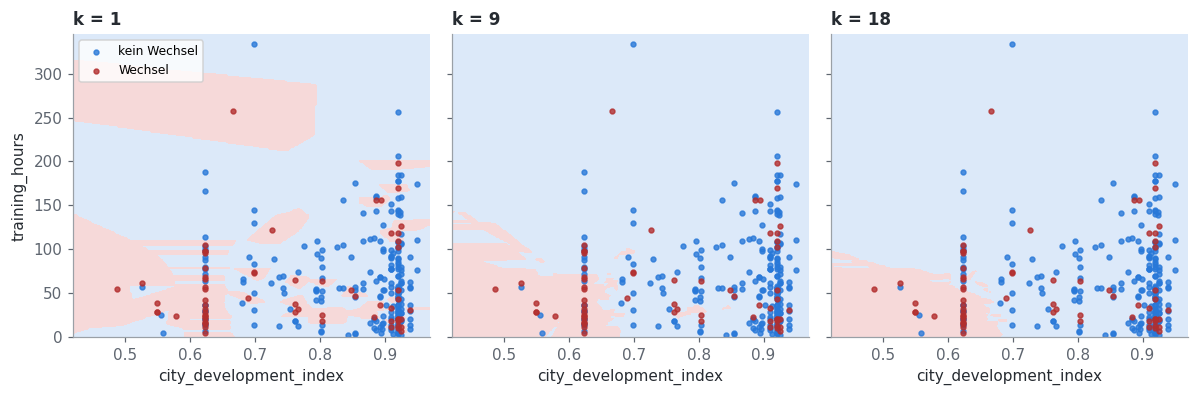

In [15]:
small = rng.choice(len(X_two), size=300, replace=False)

fig, axes = plt.subplots(1, 3, figsize=(11, 3.7), sharey=True)
for ax, k in zip(axes, [1, 9, 18]):
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=k))
    model.fit(X_two[small], y_two[small])
    plot_boundary(ax, model, X_two[small], y_two[small], point_size=10)
    ax.set_title(f"k = {k}", loc="left", color=INK, fontsize=11, fontweight="bold")
axes[0].set_ylabel("training_hours")
axes[0].legend(loc="upper left", fontsize=8, frameon=True)
plt.tight_layout()
plt.show()

**So liest du die Grafik**

- Die Achsen und Farben sind dieselben wie in 5c: Hintergrund = Vorhersage, Punktfarbe = Wahrheit.
- Alle drei Bilder zeigen dieselben 300 Personen. Geändert hat sich nur k. Achte also darauf, wie sich die **Flächen** verändern.

**Beispiel:** Oben im linken Bild liegt ein einzelner roter Punkt bei Index 0,67 und etwa 260 Stunden. Bei k = 1 bekommt er eine eigene große rosa Fläche, denn er entscheidet in seiner Umgebung allein. Bei k = 9 liegt derselbe Punkt auf blauer Fläche, weil er von seinen Nachbarn überstimmt wird. Das Modell behandelt ihn jetzt als Ausnahme und nicht mehr als Regel.

**Was wir sehen:**

- **k = 1:** Die Grenze folgt einzelnen Punkten, überall entstehen kleine Inseln. Das Modell ist komplex und neigt zu **Overfitting**.
- **k = 9:** Die Inseln sind weitgehend verschwunden.
- **k = 18:** Die Grenze ist noch glatter, das Modell ist einfacher. Bei zu großem k droht **Underfitting**.

Bei nur 300 Personen wirkt dieser Effekt schneller als bei unseren 15.326. Deshalb passt zum vollen Datensatz ein viel größeres k.

## 9. Hyperparameter-Tuning

Neben k gibt es zwei weitere Stellschrauben:

- `weights`: `uniform` gibt jedem Nachbarn eine Stimme, bei `distance` zählen nähere Nachbarn mehr.
- `p`: die Distanz. `p=2` ist die euklidische Distanz (Luftlinie), `p=1` die Manhattan-Distanz (Summe der Einzelabstände).

**Warum nur diese k-Werte?** Schritt 8 hat gezeigt, dass sehr kleine k klar schlechter sind, darum beginnt die Suche bei 15. Alle Werte sind ungerade, damit es bei zwei Klassen und gleichen Stimmen kein Unentschieden gibt.

`GridSearchCV` probiert alle Kombinationen mit 5-facher CV aus und bewertet sie nach ROC AUC. Am Ende trainiert es die beste Kombination automatisch noch einmal auf allen Trainingsdaten.

In [16]:
param_grid = {
    "knn__n_neighbors": [15, 25, 41, 75, 101, 151, 201, 301, 401],
    "knn__weights": ["uniform", "distance"],
    "knn__p": [1, 2],
}

grid = GridSearchCV(make_knn(BEST_ENCODING), param_grid, cv=cv,
                    scoring="roc_auc", n_jobs=-1).fit(X_train, y_train)

print("Beste Kombination:", grid.best_params_)
print(f"Bester CV-AUC: {grid.best_score_:.3f} ± {grid.cv_results_['std_test_score'][grid.best_index_]:.3f}")

top = pd.DataFrame(grid.cv_results_).sort_values("rank_test_score").head(6)
display(top[["param_knn__n_neighbors", "param_knn__weights", "param_knn__p",
             "mean_test_score", "std_test_score"]]
        .set_axis(["k", "weights", "p", "AUC Mittelwert", "AUC Streuung"], axis=1).round(4))

best_model = grid.best_estimator_

/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/joblib/externals/loky/process_executor.py:787: UserWarning: A worker stopped while some jobs were given to the executor. This can be caused by a too short worker timeout or by a memory leak.
  warnings.warn(


Beste Kombination: {'knn__n_neighbors': 151, 'knn__p': 1, 'knn__weights': 'uniform'}
Bester CV-AUC: 0.785 ± 0.009


,k,weights,p,AUC Mittelwert,AUC Streuung
20,151,uniform,1,0.7851,0.0090
22,151,uniform,2,0.7849,0.0103
26,201,uniform,2,0.7846,0.0107
24,201,uniform,1,0.7843,0.0096
16,101,uniform,1,0.7839,0.0093
30,301,uniform,2,0.7839,0.0110


**Ergebnis:** Die beste Kombination ist k = 151, `uniform`, Manhattan-Distanz (`p = 1`) mit einem CV-AUC von 0,785 ± 0,009.

**Einordnung:** Die sechs besten Kombinationen liegen nur 0,0012 auseinander, weit weniger als die Streuung von rund 0,01. Sie sind praktisch gleich gut, die genaue Wahl ist also nicht kritisch. Wichtig ist: k = 151 liegt mitten im Suchbereich (15 bis 401), wir müssen ihn also nicht erweitern.

### 9b. Hilft wirklich jedes Feature?

Bei kNN zählt jede Spalte bei der Distanz mit. Ein unwichtiges Feature macht Personen scheinbar unähnlich, obwohl der Unterschied für den Jobwechsel keine Rolle spielt. "Mehr Variablen" ist also nicht automatisch besser.

**Vorgehen (Leave-one-feature-out):** Wir lassen jedes der 10 Features einmal weg und messen den AUC mit denselben fünf Folds und den besten Parametern aus Schritt 9. Sinkt der AUC, hat das Feature geholfen. Steigt er, hat es eher gestört.

**Regel, vorab festgelegt:** Ein Feature wird nur entfernt, wenn der mittlere AUC ohne es um mehr als 0,005 steigt **und** das in allen fünf Folds der Fall ist. So werfen wir nichts wegen eines zufälligen Mini-Unterschieds hinaus.

Alle 10 Features: AUC = 0.7851 ± 0.0090


,weggelassen,AUC-Änderung,Folds besser ohne
0,city_development_index,-0.0792,0
1,company_size,-0.0049,1
2,major_discipline,-0.0039,0
3,last_new_job,-0.0024,1
4,relevant_experience,-0.0018,1
5,company_type,-0.0014,2
6,enrolled_university,-0.0013,1
7,education_level,-0.0008,0
8,experience,-0.0007,2
9,training_hours,0.0020,4


Zu entfernende Features nach der Regel: []


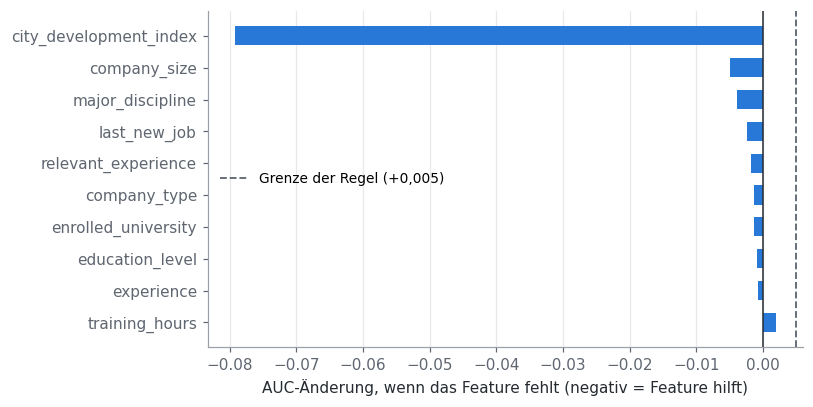

In [17]:
def cv_auc(exclude=()):
    model = make_knn(BEST_ENCODING, exclude=exclude).set_params(**grid.best_params_)
    return cross_validate(model, X_train.drop(columns=list(exclude)), y_train, cv=cv,
                          scoring="roc_auc", n_jobs=-1)["test_score"]


auc_all = cv_auc()
print(f"Alle 10 Features: AUC = {auc_all.mean():.4f} ± {auc_all.std():.4f}")

rows = []
for feature in X_train.columns:
    diff = cv_auc(exclude=(feature,)) - auc_all      # Vergleich je Fold, weil die Folds identisch sind
    rows.append({"weggelassen": feature, "AUC-Änderung": diff.mean(),
                 "Folds besser ohne": int((diff > 0).sum())})

feature_check = pd.DataFrame(rows).sort_values("AUC-Änderung").reset_index(drop=True)
display(feature_check.round(4))

features_to_drop = feature_check.query("`AUC-Änderung` > 0.005 and `Folds besser ohne` == 5")["weggelassen"].tolist()
print("Zu entfernende Features nach der Regel:", features_to_drop)

fig, ax = plt.subplots(figsize=(7.5, 3.8))
ordered = feature_check.iloc[::-1]
ax.barh(ordered["weggelassen"], ordered["AUC-Änderung"], color=BLUE, height=0.6)
ax.axvline(0, color=INK, lw=1)
ax.axvline(0.005, color="#5F6670", ls="--", lw=1.2, label="Grenze der Regel (+0,005)")
ax.set_xlabel("AUC-Änderung, wenn das Feature fehlt (negativ = Feature hilft)")
ax.grid(axis="y", visible=False)
ax.legend(loc="center left", fontsize=9)
plt.tight_layout()
plt.show()

**So liest du die Grafik**

- **Jeder Balken** zeigt, wie sich der AUC ändert, wenn genau dieses Feature fehlt.
- **Balken nach links (negativ):** Ohne das Feature wird das Modell schlechter, es hilft also.
- **Balken nach rechts (positiv):** Ohne das Feature wird das Modell besser, es stört also eher.
- **Gestrichelte Linie:** Erst ein Balken jenseits von +0,005 kommt nach unserer Regel für das Entfernen infrage.

**Beispiel:** Der Balken von `city_development_index` reicht bis −0,079. Der AUC fällt ohne dieses Feature also von 0,785 auf etwa 0,706. Der Balken von `training_hours` zeigt +0,002: Der AUC stiege auf etwa 0,787, die gestrichelte Linie wird aber nicht erreicht.

**Ergebnis:** Nach unserer Regel wird kein Feature entfernt, das Modell behält also alle 10.

- **`city_development_index` ist mit Abstand am wichtigsten.** Ohne ihn fällt der AUC um 0,079.
- **Die übrigen Features tragen jeweils wenig bei.** Ihr Weglassen ändert den AUC um höchstens 0,005. Das heißt nicht, dass sie nutzlos sind: Verwandte Spalten wie `company_size` und `company_type` können sich gegenseitig ersetzen, sodass der Verlust einer einzelnen Spalte kaum auffällt.
- **`training_hours` ist der einzige Grenzfall.** Ohne dieses Feature steigt der AUC in 4 von 5 Folds, im Mittel aber nur um 0,002. Das liegt deutlich unter der Grenze von 0,005 und unter der Streuung von rund 0,01. Es bleibt deshalb im Modell. Das passt zum Bild in 5c, in dem die Trainingsstunden kaum eine Rolle spielen.

## 10. Schwellenwert aus Kosten wählen

kNN liefert über `predict_proba` den **Anteil der Nachbarn, die wechseln**. `predict` sagt "Wechsel", sobald dieser Anteil mindestens 0,5 beträgt. Dieser Wert ist aber keine Eigenschaft des Modells, sondern eine **geschäftliche Entscheidung**.

**Warum findet eine niedrigere Schwelle mehr Wechselwillige?** Das Modell und seine Anteile bleiben genau gleich. Die Schwelle legt nur fest, ab welchem Anteil wechselnder Nachbarn eine Person als "Wechsel" gilt:

| Anteil wechselnder Nachbarn | Schwelle 0,50 | Schwelle 0,32 |
|---|---|---|
| 60 % | Wechsel | Wechsel |
| 40 % | kein Wechsel | **Wechsel** |
| 20 % | kein Wechsel | kein Wechsel |

Mit einer niedrigeren Schwelle werden mehr Personen markiert. Darunter sind mehr echte Wechselwillige, aber auch mehr Fehlalarme. Die Kosten beantworten nur die Frage, **wie weit sich das Senken lohnt**: Je teurer eine übersehene Person im Vergleich zu einem Fehlalarm ist, desto niedriger sollte die Schwelle liegen.

**Annahme zu den Kosten (von uns gesetzt, nicht aus den Daten):**

| Fehler | Bedeutung | Annahme |
|---|---|---|
| False Positive | Recruiting spricht jemanden an, der gar nicht wechseln will | 100 € Aufwand |
| False Negative | Wechselwillige Person wird übersehen und muss teurer extern gefunden werden | 300 € |

**Woher kommt der Richtwert aus der Vorlesung?** Sprechen wir eine Person mit Wechselwahrscheinlichkeit p an, zahlen wir im Erwartungswert (1 − p) · 100 € für einen möglichen Fehlalarm. Sprechen wir sie nicht an, zahlen wir p · 300 € für eine mögliche übersehene Person. Ansprechen lohnt sich, sobald p · 300 > (1 − p) · 100, also ab p > 100 / (100 + 300) = 0,25.

Wir bestimmen den Schwellenwert aus **Out-of-Fold-Wahrscheinlichkeiten** der Trainingsdaten: Jede Person bekommt eine Vorhersage von einem Modell, das sie nicht gesehen hat. Das ist nötig, weil jede Person in den Trainingsdaten sonst zu ihren eigenen Nachbarn zählen und ihre eigene Antwort mitwählen würde. Die Folie zeigt die Kostenkurve auf dem Testset, um das Prinzip zu erklären. Für eine echte Entscheidung darf das Testset aber nicht mitreden.

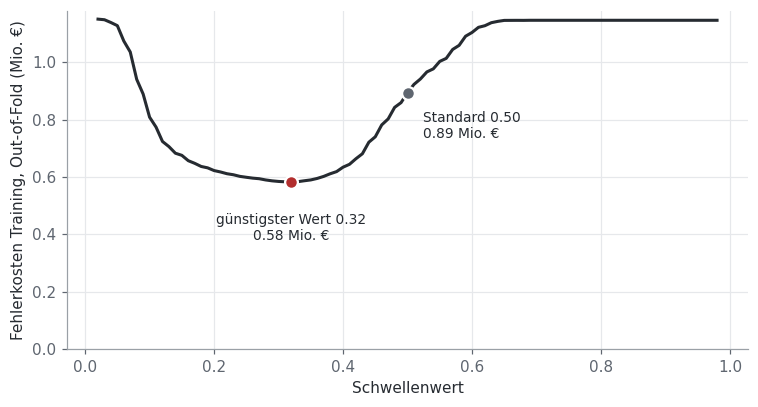

Theorie: 0.25 | empirisch günstigster Wert: 0.32
Kosten bei 0.50: 894,500 € | Kosten bei 0.32: 583,400 €


In [18]:
COST_FP, COST_FN = 100, 300     # Annahmen: hier anpassen, wenn ihr andere Kosten begründet


def total_cost(y_true, y_pred):
    tn, fp, fn, tp = confusion_matrix(y_true, y_pred).ravel()
    return fp * COST_FP + fn * COST_FN


oof_proba = cross_val_predict(best_model, X_train, y_train, cv=cv,
                              method="predict_proba", n_jobs=-1)[:, 1]

thresholds = np.round(np.arange(0.02, 0.99, 0.01), 2)
costs = np.array([total_cost(y_train, (oof_proba >= t).astype(int)) for t in thresholds])

THRESHOLD = float(thresholds[costs.argmin()])
cost_05 = total_cost(y_train, (oof_proba >= 0.5).astype(int))

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(thresholds, costs / 1e6, color=INK)
ax.scatter([THRESHOLD], [costs.min() / 1e6], s=70, color=RED, zorder=3, edgecolor="white", linewidth=1.5)
ax.scatter([0.5], [cost_05 / 1e6], s=70, color="#5F6670", zorder=3, edgecolor="white", linewidth=1.5)
ax.annotate(f"günstigster Wert {THRESHOLD:.2f}\n{costs.min()/1e6:.2f} Mio. €", (THRESHOLD, costs.min() / 1e6),
            xytext=(0, -38), textcoords="offset points", ha="center", color=INK, fontsize=9)
ax.annotate(f"Standard 0.50\n{cost_05/1e6:.2f} Mio. €", (0.5, cost_05 / 1e6),
            xytext=(10, -30), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("Schwellenwert")
ax.set_ylabel("Fehlerkosten Training, Out-of-Fold (Mio. €)")
ax.set_ylim(0, None)
plt.tight_layout()
plt.show()

print(f"Theorie: {COST_FP / (COST_FP + COST_FN):.2f} | empirisch günstigster Wert: {THRESHOLD:.2f}")
print(f"Kosten bei 0.50: {cost_05:,} € | Kosten bei {THRESHOLD:.2f}: {costs.min():,} €")

**So liest du die Grafik**

- **x-Achse:** die Schwelle, ab der eine Person als "Wechsel" gilt.
- **y-Achse:** die gesamten Fehlerkosten auf den Trainingsdaten bei dieser Schwelle. Je niedriger die Linie, desto besser.
- **Roter Punkt:** die günstigste Schwelle. **Grauer Punkt:** die Standard-Schwelle 0,5.

**Beispiel:** Bei 0,50 kosten die Fehler 0,89 Mio. €, bei 0,32 nur 0,58 Mio. €. Ganz links werden fast alle angesprochen, dann entstehen rund 11.500 Fehlalarme à 100 €, also etwa 1,15 Mio. €. Ganz rechts wird niemand angesprochen, dann werden rund 3.800 Personen à 300 € übersehen, also ebenfalls etwa 1,15 Mio. €. Das Minimum liegt dazwischen, weil beide Extreme teuer sind.

**Ergebnis:** Auf den Trainingsdaten sind die Kosten bei einer Schwelle von 0,32 am niedrigsten: 583.400 € statt 894.500 € bei 0,50.

**Warum nicht genau 0,25?** Die Formel gilt für exakt kalibrierte Wahrscheinlichkeiten, und kNN liefert nur Nachbarschaftsanteile. Außerdem ist die Kurve zwischen etwa 0,25 und 0,35 ziemlich flach. Wir legen 0,32 fest und verändern den Wert danach nicht mehr.

## 11. Einmalige Auswertung auf dem Testset

Jetzt ist alles festgelegt: Encoding, k, Gewichtung, Distanz und Schwellenwert. Erst hier kommt das Testset ins Spiel. **Nach dieser Zelle ändern wir nichts mehr am Modell**, sonst wäre das Ergebnis zu optimistisch.

**Warum wäre es zu optimistisch?** Würden wir so lange anpassen, bis das Testset gut aussieht, hätte sich das Modell indirekt an genau diese Personen angepasst. Der Wert würde dann nicht mehr zeigen, wie gut es bei wirklich neuen Personen ist.

`best_model` wurde von `GridSearchCV` bereits auf allen 15.326 Trainingspersonen neu gelernt. Es nutzt also mehr Daten als die Modelle in den einzelnen Folds.

Wir werten drei Regeln aus: die Baseline, das Modell mit Standard-Schwelle 0,5 und das Modell mit der Kosten-Schwelle.

In [19]:
test_proba = best_model.predict_proba(X_test)[:, 1]
test_auc = roc_auc_score(y_test, test_proba)

decisions = {
    "Baseline (immer 'kein Wechsel')": np.zeros(len(y_test), dtype=int),
    "kNN, Schwelle 0.50": (test_proba >= 0.5).astype(int),
    f"kNN, Schwelle {THRESHOLD:.2f}": (test_proba >= THRESHOLD).astype(int),
}

summary = pd.DataFrame([{
    "Regel": name,
    "Accuracy": accuracy_score(y_test, pred),
    "Precision": precision_score(y_test, pred, zero_division=0),
    "Recall": recall_score(y_test, pred),
    "F1": f1_score(y_test, pred),
    "Kosten (€)": total_cost(y_test, pred),
} for name, pred in decisions.items()]).set_index("Regel")

print(f"Test ROC AUC: {test_auc:.3f}   (Cross-Validation: {grid.best_score_:.3f})")
display(summary.round(3))

Test ROC AUC: 0.797   (Cross-Validation: 0.785)


,Accuracy,Precision,Recall,F1,Kosten (€)
Regel,,,,,
Baseline (immer 'kein Wechsel'),0.751,0.000,0.000,0.000,286500
"kNN, Schwelle 0.50",0.775,0.580,0.350,0.436,210500
"kNN, Schwelle 0.32",0.756,0.507,0.765,0.610,138200


### Confusion Matrix

Zeilen zeigen die Wahrheit, Spalten die Vorhersage. "Positiv" bedeutet: Das Modell sagt einen Wechsel voraus.

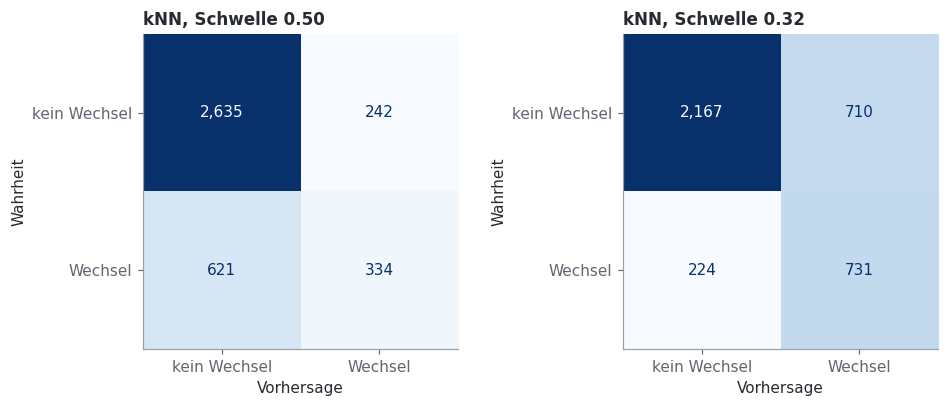

In [20]:
names = list(decisions)[1:]
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8))
for ax, name in zip(axes, names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, decisions[name], ax=ax, cmap="Blues", colorbar=False, values_format=",d",
        display_labels=["kein Wechsel", "Wechsel"])
    ax.grid(False)
    ax.set_title(name, loc="left", color=INK, fontsize=11, fontweight="bold")
    ax.set_xlabel("Vorhersage")
    ax.set_ylabel("Wahrheit")
plt.tight_layout()
plt.show()

**So liest du die Grafik**

- **Zeilen = Wahrheit, Spalten = Vorhersage.** Je dunkler ein Feld, desto mehr Personen enthält es.
- **Oben links:** richtig als "kein Wechsel" erkannt (True Negative). **Unten rechts:** richtig als "Wechsel" erkannt (True Positive).
- **Oben rechts:** Fehlalarm (False Positive). **Unten links:** übersehene Person (False Negative).

**Beispiel (linkes Bild, Schwelle 0,50):** Unten rechts stehen 334 gefundene, unten links 621 übersehene Wechselwillige. Der Recall ist also 334 / (334 + 621) = 35,0 %. In der rechten Spalte stehen 334 richtige und 242 falsche Markierungen, die Precision ist also 334 / (334 + 242) = 58,0 %.

Im rechten Bild (Schwelle 0,32) sinken die übersehenen Personen von 621 auf 224, die Fehlalarme steigen dafür von 242 auf 710.

### ROC-Kurve

Jeder Schwellenwert ist ein Punkt auf der Kurve. Die Fläche darunter (AUC) ist die Wahrscheinlichkeit, dass eine zufällig gezogene wechselwillige Person ein höheres Risiko bekommt als eine zufällig gezogene Person, die nicht wechselt.

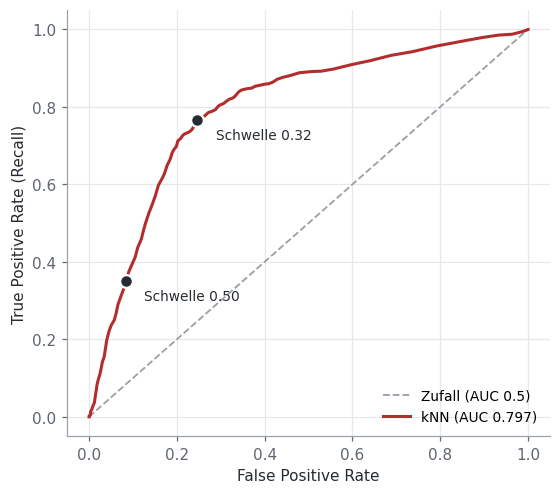

In [21]:
fpr, tpr, _ = roc_curve(y_test, test_proba)

fig, ax = plt.subplots(figsize=(5.2, 4.6))
ax.plot([0, 1], [0, 1], ls="--", lw=1.2, color="#9AA0A6", label="Zufall (AUC 0.5)")
ax.plot(fpr, tpr, color=RED, label=f"kNN (AUC {test_auc:.3f})")
for t, dx in [(0.5, 12), (THRESHOLD, 12)]:
    pred = (test_proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    x, y = fp / (fp + tn), tp / (tp + fn)
    ax.scatter([x], [y], s=70, color=INK, zorder=3, edgecolor="white", linewidth=1.5)
    ax.annotate(f"Schwelle {t:.2f}", (x, y), xytext=(dx, -12), textcoords="offset points", color=INK, fontsize=9)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate (Recall)")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.show()

**So liest du die Grafik**

- **x-Achse:** Anteil der Nichtwechsler, die fälschlich markiert werden. Nach rechts ist schlecht.
- **y-Achse:** Anteil der Wechselwilligen, die gefunden werden (Recall). Nach oben ist gut.
- **Gestrichelte Diagonale:** reines Raten. Je weiter die rote Kurve darüber liegt, desto besser sortiert das Modell.
- **Jede Stelle auf der Kurve** entspricht einer Schwelle. Das Modell bleibt dasselbe, nur die Schwelle wandert.

**Beispiel:** Der Punkt "Schwelle 0.50" liegt bei x ≈ 0,08 und y = 0,35: 8 % der Nichtwechsler werden markiert, 35 % der Wechselwilligen gefunden. Der Punkt "Schwelle 0.32" liegt bei x ≈ 0,25 und y ≈ 0,77. Beim Senken der Schwelle findet das Modell also 42 Prozentpunkte mehr Wechselwillige und markiert 16 Prozentpunkte mehr Nichtwechsler.

### Ergebnis auf dem Testset

| Regel | Accuracy | Precision | Recall | F1 | Kosten |
|---|---|---|---|---|---|
| Baseline | 75,1 % | 0 | 0 | 0 | 286.500 € |
| kNN, Schwelle 0,50 | 77,5 % | 58,0 % | 35,0 % | 0,44 | 210.500 € |
| kNN, Schwelle 0,32 | 75,6 % | 50,7 % | 76,5 % | 0,61 | 138.200 € |

- **Generalisierung:** Der Test-AUC von 0,797 passt zum CV-AUC von 0,785. Der Unterschied liegt etwa bei der Streuung zwischen den Folds. Dass der Testwert etwas höher ist, ist also kein Zeichen für ein besseres Modell.
- **Schwelle 0,50:** Das Modell findet nur 334 von 955 Wechselwilligen.
- **Schwelle 0,32:** Es findet 731 von 955. Dafür steigen die Fehlalarme von 242 auf 710, ungefähr jede zweite angesprochene Person will wirklich wechseln.
- **Accuracy gegen Kosten:** Die Accuracy sinkt bei 0,32 von 77,5 % auf 75,6 %, die Kosten fallen aber um 34 %. Gegenüber der Baseline sind es 52 % weniger. Die Accuracy allein hätte uns zur schlechteren Entscheidung geführt.

## 12. Fazit

**Endgültiges Modell:** alle 10 Features, one-hot-Encoding, `StandardScaler`, kNN mit k = 151, `uniform`, Manhattan-Distanz, Schwelle 0,32.

| Erkenntnis | Beleg |
|---|---|
| Skalierung ist Pflicht | AUC 0,657 ohne, 0,755 mit Skalierung |
| Kleines k lernt auswendig | k = 1: 99,8 % Accuracy im Training, 71,2 % auf ungesehenen Daten |
| Ab etwa k = 75 ändert sich wenig | CV-AUC bleibt bei 0,783 bis 0,785 |
| Ein einzelner Holdout-Split reicht für die Wahl von k nicht | Holdout: Maximum bei k = 11, aber kaum vom Rauschen zu trennen. Die Cross-Validation wählt k = 151 |
| `city_development_index` ist das wichtigste Feature, kein Feature musste entfernt werden | AUC −0,079 ohne dieses Feature, bei den anderen höchstens ±0,005 |
| Das Modell trennt die Klassen ordentlich | Test-AUC 0,797 |
| Der Schwellenwert ist die wirkungsvollste Entscheidung | Kosten 138.200 € statt 210.500 € |

**Grenzen:**

- Die Kosten von 100 € und 300 € sind **unsere Annahmen**. Mit anderen Kosten ändert sich die Schwelle, sie stehen deshalb als Variablen in Schritt 10.
- Die Kosten bewerten nur Fehler. Mögliche Gewinne durch richtige Treffer sind nicht enthalten.
- kNN muss für jede Vorhersage alle 15.326 Trainingspersonen speichern und durchsuchen und liefert keine lesbaren Gewichte.

**Nächster Schritt:** Für die Präsentation fehlt noch die logistische Regression. Sie sollte dieselben Daten, dieselben fünf Folds (`cv`) und dieselben Kosten verwenden, damit beide Modelle vergleichbar sind.